# Step #1 Load the Data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

RANDOM_SEED = 700
FIGURE_DIR = Path(r"C:\Users\ffollonier\workspace\relataly_new\public\wp-content\uploads\2026\08")
phrases = {
    "negative": ["terrible service", "the product failed", "very disappointing", "I dislike this update", "support was unhelpful", "poor quality item"],
    "neutral": ["the package arrived today", "the meeting starts at noon", "this is a standard feature", "the item is blue", "the report has ten pages", "delivery is scheduled"],
    "positive": ["excellent service", "I love this product", "a wonderful improvement", "the update works well", "support was helpful", "great quality item"],
}
rows = [{"text": f"{phrase} example {i}", "sentiment": label} for label, items in phrases.items() for phrase in items for i in range(5)]
data = pd.DataFrame(rows)
train_df, test_df = train_test_split(data, test_size=0.30, stratify=data["sentiment"], random_state=RANDOM_SEED)
print(train_df.shape, test_df.shape)

(63, 2) (27, 2)


In [2]:
assert train_df.index.intersection(test_df.index).empty
print("The holdout remains untouched until final evaluation.")

The holdout remains untouched until final evaluation.


# Step #2 Clean and Preprocess the Data

In [3]:
train_df = train_df.assign(text_length=train_df["text"].str.len())
test_df = test_df.assign(text_length=test_df["text"].str.len())
print(train_df.groupby("sentiment")["text_length"].describe()[["mean", "min", "max"]])

                mean   min   max
sentiment                       
negative   28.142857  26.0  31.0
neutral    32.619048  26.0  36.0
positive   29.523810  27.0  33.0


# Step #3 Explore the Data

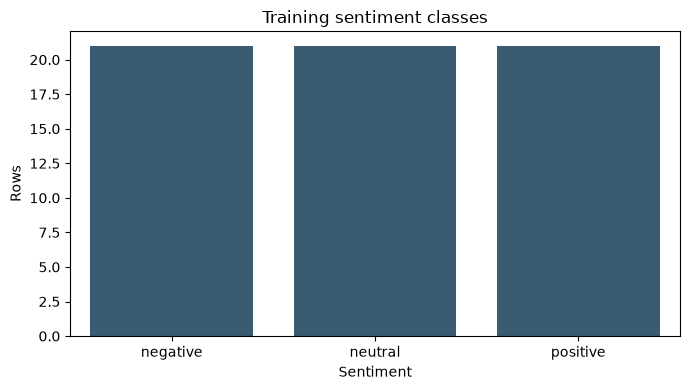

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=train_df, x="sentiment", order=["negative", "neutral", "positive"], color="#315c7d", ax=ax)
ax.set(title="Training sentiment classes", xlabel="Sentiment", ylabel="Rows")
fig.tight_layout()
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURE_DIR / "700-sentiment-class-balance.png", dpi=160, bbox_inches="tight")
plt.show()

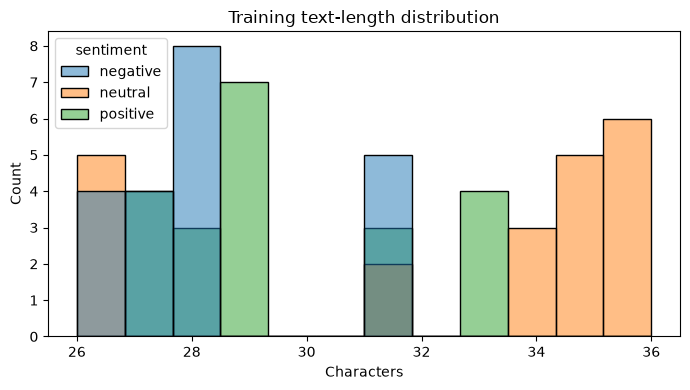

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=train_df, x="text_length", hue="sentiment", multiple="layer", bins=12, ax=ax)
ax.set(title="Training text-length distribution", xlabel="Characters")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "700-sentiment-text-length.png", dpi=160, bbox_inches="tight")
plt.show()

# Step #4 Train a Logistic Regression Classifier

              precision  recall  f1-score  support
negative            1.0     1.0       1.0      9.0
neutral             1.0     1.0       1.0      9.0
positive            1.0     1.0       1.0      9.0
accuracy            1.0     1.0       1.0      1.0
macro avg           1.0     1.0       1.0     27.0
weighted avg        1.0     1.0       1.0     27.0


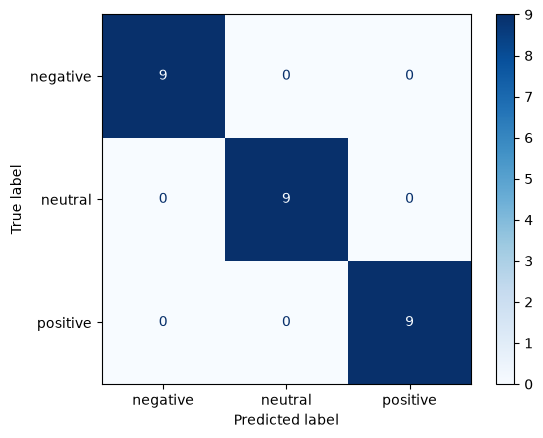

In [6]:
def evaluate_model(name, estimator):
    estimator.fit(train_df["text"], train_df["sentiment"])
    predictions = estimator.predict(test_df["text"])
    report = classification_report(test_df["sentiment"], predictions, output_dict=True, zero_division=0)
    return {
        "model": name,
        "macro_f1": f1_score(test_df["sentiment"], predictions, average="macro"),
        "predictions": predictions,
        "report": report,
    }

logistic_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=1)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)),
])
logistic_result = evaluate_model("Logistic regression", logistic_pipeline)
print(pd.DataFrame(logistic_result["report"]).T)
ConfusionMatrixDisplay.from_predictions(test_df["sentiment"], logistic_result["predictions"], cmap="Blues")
plt.show()

# Step #4b Train a Bayes Classifier

              precision  recall  f1-score  support
negative            1.0     1.0       1.0      9.0
neutral             1.0     1.0       1.0      9.0
positive            1.0     1.0       1.0      9.0
accuracy            1.0     1.0       1.0      1.0
macro avg           1.0     1.0       1.0     27.0
weighted avg        1.0     1.0       1.0     27.0


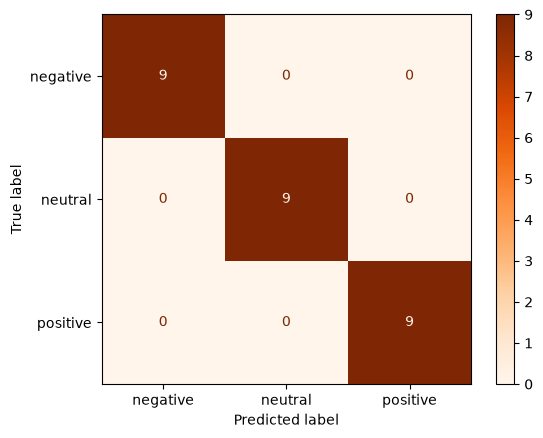

In [7]:
bayes_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=1)),
    ("classifier", MultinomialNB(alpha=0.5)),
])
bayes_result = evaluate_model("Multinomial naive Bayes", bayes_pipeline)
print(pd.DataFrame(bayes_result["report"]).T)
ConfusionMatrixDisplay.from_predictions(test_df["sentiment"], bayes_result["predictions"], cmap="Oranges")
plt.show()

# Step #5 Compare Classifier Performance

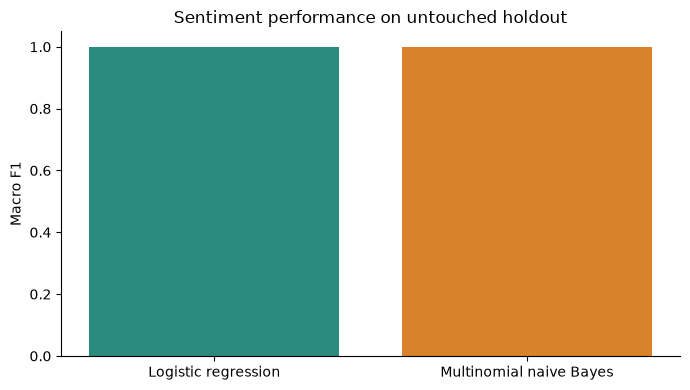

,model,macro_f1
0,Logistic regression,1.0
1,Multinomial naive Bayes,1.0


In [8]:
performance_df = pd.DataFrame([
    {"model": logistic_result["model"], "macro_f1": logistic_result["macro_f1"]},
    {"model": bayes_result["model"], "macro_f1": bayes_result["macro_f1"]},
]).sort_values("macro_f1", ascending=False)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(performance_df["model"], performance_df["macro_f1"], color=["#2b8c7e", "#d9822b"])
ax.set(title="Sentiment performance on untouched holdout", ylabel="Macro F1", ylim=(0, 1.05))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "700-sentiment-model-comparison.png", dpi=160, bbox_inches="tight")
plt.show()
performance_df

# Step #6 Make Test Predictions

In [9]:
examples = ["Mondays are terrible", "I love this product", "The package arrived today"]
for phrase, prediction in zip(examples, logistic_pipeline.predict(examples)):
    print(f"{phrase} -> {prediction}")
print("Caveat: this small synthetic fixture verifies the workflow, not real-world generalization, dialect coverage, or cultural validity.")

Mondays are terrible -> negative
I love this product -> positive
The package arrived today -> neutral
Caveat: this small synthetic fixture verifies the workflow, not real-world generalization, dialect coverage, or cultural validity.
